## A Leakage-Aware Machine Learning Framework for Heatwave Risk Prediction, Early Warning, and 2035 Climate Scenario Simulation

This notebook explores Rajasthan's climate patterns using daily observations from 2006 to 2025. The main focus is understanding historical heatwave trends, predicting future heatwave risk, and exploring how changing climate conditions could affect different districts.

**What is covered in this notebook?**

- **Data Exploration:** Examine the dataset, check missing values, study temperature patterns, and analyse historical heatwave trends across nine districts.
- **Data Preparation:** Construct dates, convert temperature values from Kelvin to Celsius, and prepare the data for analysis.
- **Heatwave Prediction:** Build a machine learning model to predict next-day heatwaves using past climate conditions, lag features, and rolling averages.
- **Leakage Prevention:** Avoid using same-day information to predict same-day heatwaves by using past-only features and a chronological train-test split.
- **Model Evaluation:** Assess prediction performance using ROC-AUC, PR-AUC, classification metrics, and feature importance.
- **Climate Regime Discovery:** Apply K-Means clustering to identify groups of similar climate conditions.
- **2035 Scenario Simulation:** Compare six hypothetical scenarios involving warming, reduced rainfall, soil moisture changes, and adaptation.
- **District-Level Risk Analysis:** Examine how heatwave risk may change across districts under different climate scenarios.

*The 2035 scenarios are simplified, model-based stress tests intended to explore possible changes in heatwave risk, not official climate projections.*

## 1. Import libraries

The notebook uses common Kaggle libraries. XGBoost and SHAP are optional but usually available in Kaggle environments. Fallback logic is included where possible.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except Exception:
    from sklearn.ensemble import HistGradientBoostingClassifier
    XGB_AVAILABLE = False

try:
    import shap
    SHAP_AVAILABLE = True
except Exception:
    SHAP_AVAILABLE = False

RANDOM_STATE = 42
pd.set_option("display.max_columns", 200)
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Load the dataset

The path below is written to work both in this ChatGPT-generated file and in Kaggle after uploading the CSV as an input dataset. If the first path does not exist, the notebook searches common Kaggle input folders.

In [2]:
df_raw = pd.read_csv("/kaggle/input/datasets/rupsarroy/heatwave-dataset-rajasthan-india-2006-2025/Rajasthan_Heatwave_2006_2025.csv")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (21960, 23)


,YEAR,MONTH,DAY,WIND_U10,WIND_V10,MSLP,BLH,GEOP,TEMP2M,TMAX,TMIN,DEW2M,CLOUD,RAIN,SRAD,EVAP,SOILT1,SOILM1,LAI,HEATWAVE,LAT,LON,DISTRICT
0,2006,3,1,-0.223022,-0.440903,101036.375,2020.7317,1671.1079,304.75806,303.54395,303.11963,271.71143,0.000000,0.0,3117056,-0.000023,312.75903,0.024887,0.515625,0,25.75,71.5,Barmer
1,2006,3,2,-1.344009,-0.294922,101076.440,2265.7910,1671.1079,306.45337,304.95703,304.54688,270.74316,0.000000,0.0,3131200,-0.000024,312.66943,0.024345,0.515625,0,25.75,71.5,Barmer
2,2006,3,3,-0.960449,1.522965,101033.750,3152.6023,1671.1079,307.34863,306.21167,305.95898,274.26490,0.000000,0.0,3105536,-0.000024,313.12280,0.023773,0.515625,0,25.75,71.5,Barmer
3,2006,3,4,2.704514,1.733017,100896.940,3146.9475,1671.1079,307.43457,306.70508,306.34473,272.11353,0.000000,0.0,3126528,-0.000024,314.12085,0.023147,0.515625,0,25.75,71.5,Barmer
4,2006,3,5,2.717834,2.464432,101014.190,2069.5261,1671.1079,306.19507,304.88306,304.13843,273.35303,0.917175,0.0,2776448,-0.000041,312.00806,0.027964,0.515625,0,25.75,71.5,Barmer


## 3. Basic data audit

Before modeling, I check columns, missing values, districts, dates, and the heatwave class balance.

In [3]:
df = df_raw.copy()

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(20))

print("\nHeatwave class balance:")
display(df["HEATWAVE"].value_counts().rename_axis("HEATWAVE").reset_index(name="count"))

print("\nDistricts:")
display(df["DISTRICT"].value_counts())

Columns:
['YEAR', 'MONTH', 'DAY', 'WIND_U10', 'WIND_V10', 'MSLP', 'BLH', 'GEOP', 'TEMP2M', 'TMAX', 'TMIN', 'DEW2M', 'CLOUD', 'RAIN', 'SRAD', 'EVAP', 'SOILT1', 'SOILM1', 'LAI', 'HEATWAVE', 'LAT', 'LON', 'DISTRICT']

Missing values:


YEAR        0
MONTH       0
DAY         0
WIND_U10    0
WIND_V10    0
MSLP        0
BLH         0
GEOP        0
TEMP2M      0
TMAX        0
TMIN        0
DEW2M       0
CLOUD       0
RAIN        0
SRAD        0
EVAP        0
SOILT1      0
SOILM1      0
LAI         0
HEATWAVE    0
dtype: int64


Heatwave class balance:


,HEATWAVE,count
0,0,20862
1,1,1098



Districts:


DISTRICT
Barmer            2440
Bikaner           2440
Churu             2440
Jaipur            2440
Jaisalmer         2440
Jodhpur           2440
Kota              2440
Nagaur            2440
Sri Ganganagar    2440
Name: count, dtype: int64

## 4. Date construction and temperature conversion

Several temperature fields are stored in Kelvin-like scale. I convert them into Celsius for interpretation while retaining the original variables if needed.

In [4]:
df["DATE"] = pd.to_datetime(df[["YEAR", "MONTH", "DAY"]])
df = df.sort_values(["DISTRICT", "DATE"]).reset_index(drop=True)

kelvin_cols = ["TEMP2M", "TMAX", "TMIN", "DEW2M", "SOILT1"]
for col in kelvin_cols:
    if col in df.columns:
        df[f"{col}_C"] = df[col] - 273.15

print(df["DATE"].min(), "to", df["DATE"].max())
print("Number of districts:", df["DISTRICT"].nunique())

display(df[["DATE", "DISTRICT", "TEMP2M_C", "TMAX_C", "TMIN_C", "RAIN", "SOILM1", "HEATWAVE"]].head())

2006-03-01 00:00:00 to 2025-06-30 00:00:00
Number of districts: 9


,DATE,DISTRICT,TEMP2M_C,TMAX_C,TMIN_C,RAIN,SOILM1,HEATWAVE
0,2006-03-01,Barmer,31.60806,30.39395,29.96963,0.0,0.024887,0
1,2006-03-02,Barmer,33.30337,31.80703,31.39688,0.0,0.024345,0
2,2006-03-03,Barmer,34.19863,33.06167,32.80898,0.0,0.023773,0
3,2006-03-04,Barmer,34.28457,33.55508,33.19473,0.0,0.023147,0
4,2006-03-05,Barmer,33.04507,31.73306,30.98843,0.0,0.027964,0


## 5. Historical heatwave trend

This section examines the historical pattern of heatwave days by year. The purpose is descriptive: it helps me understand whether heatwave exposure is stable, seasonal, district-specific, or changing over time.

,YEAR,heatwave_days,observations,mean_tmax_c,mean_temp2m_c,mean_rain,mean_soilm1,heatwave_rate
0,2006,57,1098,36.739368,36.975364,0.000023,0.085564,0.051913
1,2007,20,1098,36.909332,37.078037,0.000030,0.092516,0.018215
2,2008,1,1098,36.299413,36.421810,0.000038,0.102459,0.000911
3,2009,60,1098,37.567231,37.755508,0.000010,0.080767,0.054645
4,2010,145,1098,39.210021,39.319469,0.000024,0.074356,0.132058


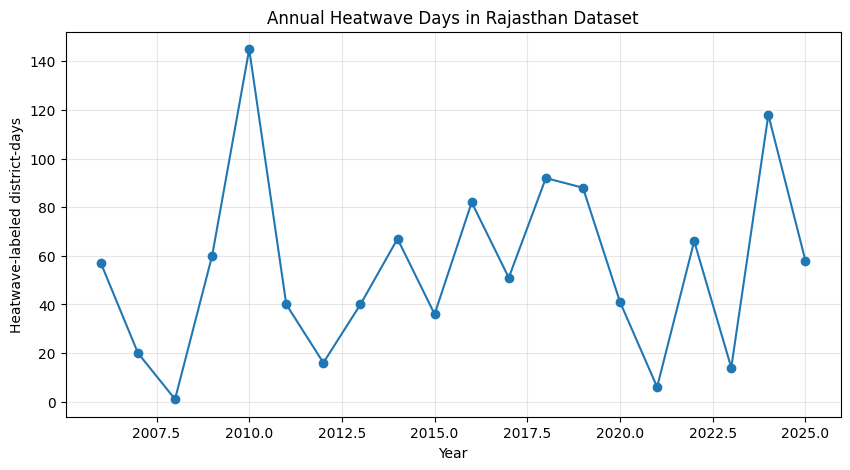

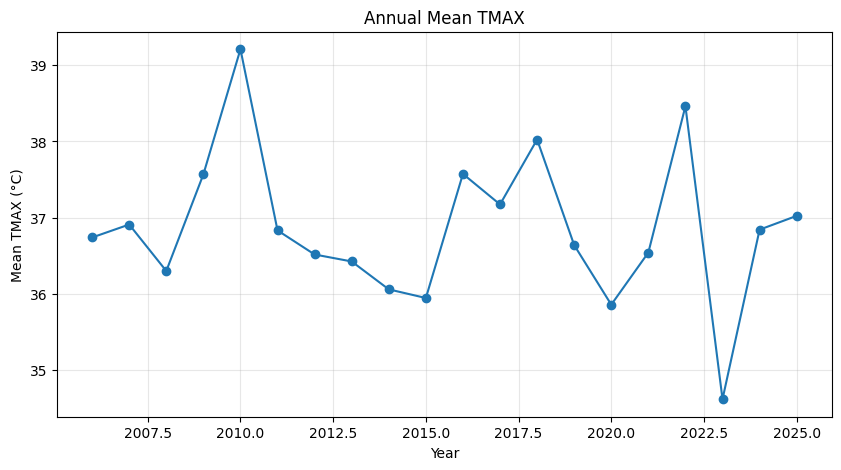

In [5]:
annual = (
    df.groupby("YEAR")
      .agg(
          heatwave_days=("HEATWAVE", "sum"),
          observations=("HEATWAVE", "size"),
          mean_tmax_c=("TMAX_C", "mean"),
          mean_temp2m_c=("TEMP2M_C", "mean"),
          mean_rain=("RAIN", "mean"),
          mean_soilm1=("SOILM1", "mean"),
      )
      .reset_index()
)
annual["heatwave_rate"] = annual["heatwave_days"] / annual["observations"]

display(annual.head())

plt.plot(annual["YEAR"], annual["heatwave_days"], marker="o")
plt.title("Annual Heatwave Days in Rajasthan Dataset")
plt.xlabel("Year")
plt.ylabel("Heatwave-labeled district-days")
plt.grid(True, alpha=0.3)
plt.show()

plt.plot(annual["YEAR"], annual["mean_tmax_c"], marker="o")
plt.title("Annual Mean TMAX")
plt.xlabel("Year")
plt.ylabel("Mean TMAX (°C)")
plt.grid(True, alpha=0.3)
plt.show()

## 6. District-level exposure

Heatwave risk is not distributed evenly across geography. This section ranks districts by cumulative heatwave exposure and average heatwave rate.

,DISTRICT,heatwave_days,observations,mean_tmax_c,mean_rain,mean_soilm1,lat,lon,heatwave_rate
1,Bikaner,220,2440,37.350409,0.000017,0.028098,28.00,73.25,0.090164
6,Kota,218,2440,37.811518,0.000032,0.198651,25.25,75.75,0.089344
2,Churu,145,2440,36.634759,0.000033,0.036559,28.25,75.00,0.059426
4,Jaisalmer,140,2440,37.260077,0.000008,0.017390,27.00,71.00,0.057377
7,Nagaur,99,2440,36.801144,0.000021,0.101262,27.25,73.75,0.040574
0,Barmer,82,2440,37.402874,0.000017,0.027708,25.75,71.50,0.033607
8,Sri Ganganagar,70,2440,35.376665,0.000041,0.151351,30.00,74.00,0.028689
5,Jodhpur,67,2440,37.040615,0.000011,0.072863,26.25,73.00,0.027459
3,Jaipur,57,2440,36.086274,0.000046,0.166193,27.00,75.75,0.023361


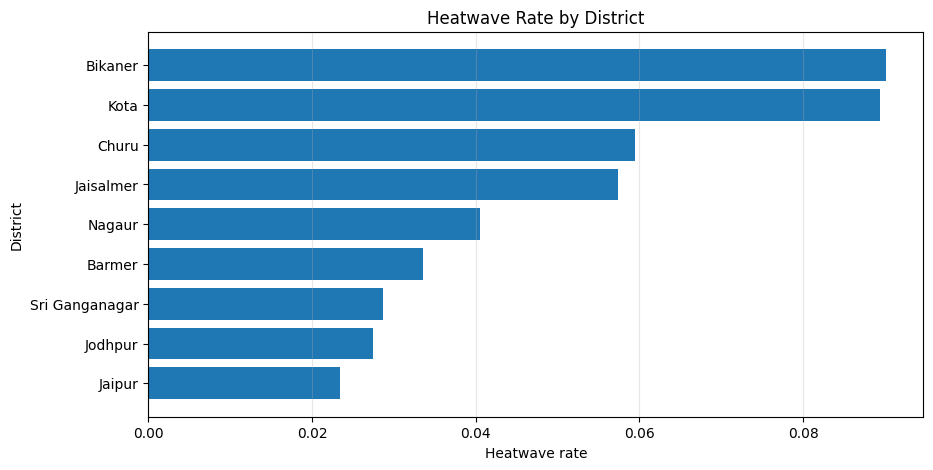

In [6]:
district_summary = (
    df.groupby("DISTRICT")
      .agg(
          heatwave_days=("HEATWAVE", "sum"),
          observations=("HEATWAVE", "size"),
          mean_tmax_c=("TMAX_C", "mean"),
          mean_rain=("RAIN", "mean"),
          mean_soilm1=("SOILM1", "mean"),
          lat=("LAT", "mean"),
          lon=("LON", "mean"),
      )
      .reset_index()
)
district_summary["heatwave_rate"] = district_summary["heatwave_days"] / district_summary["observations"]
district_summary = district_summary.sort_values("heatwave_rate", ascending=False)

display(district_summary)

plt.barh(district_summary["DISTRICT"], district_summary["heatwave_rate"])
plt.title("Heatwave Rate by District")
plt.xlabel("Heatwave rate")
plt.ylabel("District")
plt.gca().invert_yaxis()
plt.grid(True, axis="x", alpha=0.3)
plt.show()

## 7. Leakage audit: why the original perfect model was problematic

A same-day model that uses `TMAX_C`, `TEMP2M_C`, or `TEMP_RANGE` to predict same-day `HEATWAVE` can easily achieve near-perfect results. This is because a heatwave label is usually defined using temperature thresholds. In other words, the model may simply reproduce the label definition.

Therefore, I do **not** use the original same-day modeling setup as the final predictive model.

The corrected objective is:

> **Predict whether a district will experience a heatwave on the next day using only past climate information.**

This transforms the analysis from label reconstruction into a simple early-warning task.

In [7]:
# Same-day correlation is useful for diagnosing leakage risk, not for final forecasting.
same_day_features = ["TEMP2M_C", "TMAX_C", "TMIN_C", "DEW2M_C", "RAIN", "SRAD", "EVAP", "SOILM1", "LAI"]
leakage_corr = (
    df[same_day_features + ["HEATWAVE"]]
    .corr(numeric_only=True)["HEATWAVE"]
    .drop("HEATWAVE")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

print("Same-day correlations with HEATWAVE. These are diagnostic only, not final model features.")
display(leakage_corr.to_frame("corr_with_same_day_heatwave"))

Same-day correlations with HEATWAVE. These are diagnostic only, not final model features.


,corr_with_same_day_heatwave
TMIN_C,0.353791
TEMP2M_C,0.353007
TMAX_C,0.351681
EVAP,0.109400
SRAD,0.096051
SOILM1,-0.063693
LAI,-0.027469
DEW2M_C,-0.025232
RAIN,-0.022434


## 8. Build a leakage-aware next-day target

For each district, I shift the heatwave label backward by one day so that each row's target is tomorrow's heatwave status.

I then create lag and rolling features. Importantly, the final model uses only variables that would have been available before the predicted heatwave day.

In [8]:
df_model = df.sort_values(["DISTRICT", "DATE"]).copy()

df_model["HEATWAVE_NEXT_DAY"] = df_model.groupby("DISTRICT")["HEATWAVE"].shift(-1)

base_numeric_features = [
    "WIND_U10", "WIND_V10", "MSLP", "BLH", "GEOP",
    "TEMP2M_C", "TMAX_C", "TMIN_C", "DEW2M_C",
    "CLOUD", "RAIN", "SRAD", "EVAP", "SOILT1_C", "SOILM1", "LAI",
]

# Create past-only features.
for col in base_numeric_features:
    df_model[f"{col}_LAG1"] = df_model.groupby("DISTRICT")[col].shift(1)
    df_model[f"{col}_ROLL3"] = df_model.groupby("DISTRICT")[col].transform(
        lambda s: s.shift(1).rolling(3, min_periods=3).mean()
    )
    df_model[f"{col}_ROLL7"] = df_model.groupby("DISTRICT")[col].transform(
        lambda s: s.shift(1).rolling(7, min_periods=7).mean()
    )

# Past heatwave persistence features.
df_model["HEATWAVE_LAG1"] = df_model.groupby("DISTRICT")["HEATWAVE"].shift(1)
df_model["HEATWAVE_ROLL7"] = df_model.groupby("DISTRICT")["HEATWAVE"].transform(
    lambda s: s.shift(1).rolling(7, min_periods=7).mean()
)

# Seasonality features.
df_model["DAY_OF_YEAR"] = df_model["DATE"].dt.dayofyear
df_model["SIN_DOY"] = np.sin(2 * np.pi * df_model["DAY_OF_YEAR"] / 365.25)
df_model["COS_DOY"] = np.cos(2 * np.pi * df_model["DAY_OF_YEAR"] / 365.25)

# Remove rows with unavailable target/features.
df_model = df_model.dropna(subset=["HEATWAVE_NEXT_DAY"]).dropna().copy()
df_model["HEATWAVE_NEXT_DAY"] = df_model["HEATWAVE_NEXT_DAY"].astype(int)

print("Modeling shape:", df_model.shape)
print("Next-day heatwave rate:", df_model["HEATWAVE_NEXT_DAY"].mean())
display(df_model[["DATE", "DISTRICT", "HEATWAVE", "HEATWAVE_NEXT_DAY", "TMAX_C_LAG1", "TMAX_C_ROLL7"]].head())

Modeling shape: (21888, 83)
Next-day heatwave rate: 0.05016447368421053


,DATE,DISTRICT,HEATWAVE,HEATWAVE_NEXT_DAY,TMAX_C_LAG1,TMAX_C_ROLL7
7,2006-03-08,Barmer,0,0,32.53652,32.115347
8,2006-03-09,Barmer,0,0,32.51138,32.417837
9,2006-03-10,Barmer,0,0,29.16665,32.040640
10,2006-03-11,Barmer,0,0,24.27236,30.785024
11,2006-03-12,Barmer,0,0,27.25625,29.885191


## 9. Chronological train-test split

Random splitting can leak time information in climate and weather datasets. I use a chronological split: observations before 2022 are used for training, and observations from 2022 onward are used for testing.

In [9]:
lag_features = [
    c for c in df_model.columns
    if c.endswith("_LAG1") or c.endswith("_ROLL3") or c.endswith("_ROLL7")
]

model_features = lag_features + [
    "HEATWAVE_LAG1", "HEATWAVE_ROLL7",
    "SIN_DOY", "COS_DOY",
    "LAT", "LON",
    "DISTRICT",
]

# Remove accidental duplicates while preserving order.
model_features = list(dict.fromkeys(model_features))

target = "HEATWAVE_NEXT_DAY"

train_df = df_model[df_model["DATE"] < "2022-01-01"].copy()
test_df = df_model[df_model["DATE"] >= "2022-01-01"].copy()

X_train = train_df[model_features]
y_train = train_df[target]
X_test = test_df[model_features]
y_test = test_df[target]

print("Train period:", train_df["DATE"].min(), "to", train_df["DATE"].max(), "| rows:", len(train_df))
print("Test period :", test_df["DATE"].min(), "to", test_df["DATE"].max(), "| rows:", len(test_df))
print("Train positive rate:", round(y_train.mean(), 4))
print("Test positive rate :", round(y_test.mean(), 4))
print("Number of features:", len(model_features))

Train period: 2006-03-08 00:00:00 to 2021-06-30 00:00:00 | rows: 17505
Test period : 2022-03-01 00:00:00 to 2025-06-29 00:00:00 | rows: 4383
Train positive rate: 0.0481
Test positive rate : 0.0584
Number of features: 55


## 10. Baseline model

Before using XGBoost, I create a simple persistence baseline. If yesterday was a heatwave, the baseline predicts tomorrow will also be a heatwave. A good machine learning model should improve on this naive rule.

In [10]:
baseline_score = test_df["HEATWAVE_LAG1"].fillna(0).values
baseline_pred = (baseline_score >= 0.5).astype(int)

baseline_roc = roc_auc_score(y_test, baseline_score)
baseline_pr = average_precision_score(y_test, baseline_score)

print("Persistence baseline")
print("ROC-AUC:", round(baseline_roc, 4))
print("PR-AUC :", round(baseline_pr, 4))
print(classification_report(y_test, baseline_pred))

Persistence baseline
ROC-AUC: 0.7262
PR-AUC : 0.2647
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      4127
           1       0.48      0.48      0.48       256

    accuracy                           0.94      4383
   macro avg       0.73      0.73      0.73      4383
weighted avg       0.94      0.94      0.94      4383



## 11. Leakage-aware XGBoost model

This model predicts next-day heatwave risk using only lagged/rolling variables, district information, geographic coordinates, and seasonality. Because heatwaves are relatively rare, I use class weighting through `scale_pos_weight`.

In [11]:
categorical_features = ["DISTRICT"]
numeric_features = [c for c in model_features if c not in categorical_features]

preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features),
    ]
)

scale_pos_weight = (y_train == 0).sum() / max(1, (y_train == 1).sum())

if XGB_AVAILABLE:
    model = XGBClassifier(
        n_estimators=220,
        max_depth=3,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=3,
        reg_lambda=2.0,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        scale_pos_weight=scale_pos_weight,
        n_jobs=2,
    )
else:
    model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=15,
        random_state=RANDOM_STATE,
        class_weight="balanced",
    )

clf = Pipeline(steps=[("preprocess", preprocess), ("model", model)])
clf.fit(X_train, y_train)

proba_test = clf.predict_proba(X_test)[:, 1]
pred_default = (proba_test >= 0.5).astype(int)

roc = roc_auc_score(y_test, proba_test)
pr_auc = average_precision_score(y_test, proba_test)

print("Model:", "XGBoost" if XGB_AVAILABLE else "HistGradientBoosting")
print("ROC-AUC:", round(roc, 4))
print("PR-AUC :", round(pr_auc, 4))
print(classification_report(y_test, pred_default))

Model: XGBoost
ROC-AUC: 0.9521
PR-AUC : 0.5747
              precision    recall  f1-score   support

           0       0.99      0.89      0.94      4127
           1       0.32      0.88      0.47       256

    accuracy                           0.89      4383
   macro avg       0.66      0.88      0.70      4383
weighted avg       0.95      0.89      0.91      4383



## 12. Threshold tuning for early-warning use

For heatwave early warning, the default 0.5 threshold is not always ideal. Missing a dangerous heatwave may be worse than issuing a few extra warnings. I therefore calculate precision and recall at multiple thresholds.

In [12]:
threshold_rows = []
for th in np.arange(0.05, 0.95, 0.05):
    pred = (proba_test >= th).astype(int)
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / max(1, tp + fp)
    recall = tp / max(1, tp + fn)
    f1 = 2 * precision * recall / max(1e-9, precision + recall)
    threshold_rows.append({
        "threshold": round(th, 2),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.sort_values("f1", ascending=False).head(10))

best_threshold = threshold_df.sort_values("f1", ascending=False).iloc[0]["threshold"]
print("Best F1 threshold:", best_threshold)

pred_best = (proba_test >= best_threshold).astype(int)
print(classification_report(y_test, pred_best))

,threshold,precision,recall,f1,false_positives,false_negatives,true_positives
16,0.85,0.511029,0.542969,0.526515,133,117,139
14,0.75,0.415888,0.695312,0.520468,250,78,178
15,0.80,0.445378,0.621094,0.518760,198,97,159
12,0.65,0.378987,0.789062,0.512041,331,54,202
13,0.70,0.389583,0.730469,0.508152,293,69,187
11,0.60,0.360967,0.816406,0.500599,370,47,209
17,0.90,0.580311,0.437500,0.498886,81,144,112
10,0.55,0.346032,0.851562,0.492099,412,38,218
9,0.50,0.324168,0.875000,0.473073,467,32,224
8,0.45,0.308005,0.886719,0.457200,510,29,227


Best F1 threshold: 0.85
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      4127
           1       0.51      0.54      0.53       256

    accuracy                           0.94      4383
   macro avg       0.74      0.76      0.75      4383
weighted avg       0.94      0.94      0.94      4383



## 13. ROC and Precision-Recall curves

ROC-AUC can look high when the negative class dominates. PR-AUC is often more informative for rare-event warning systems.

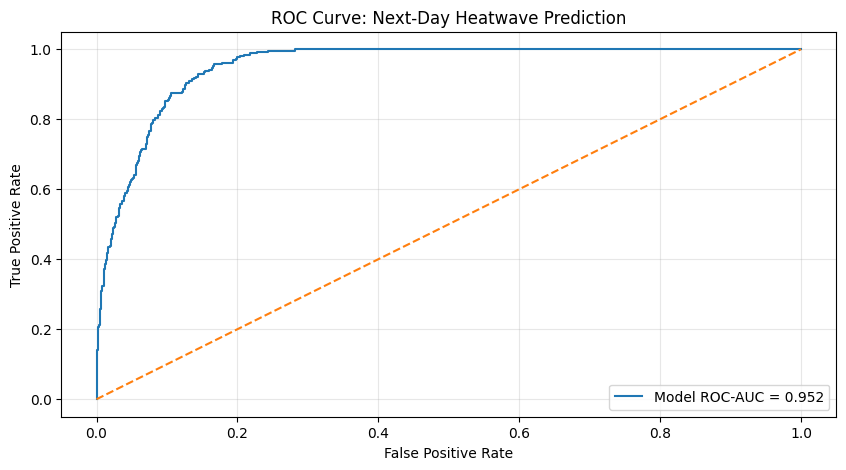

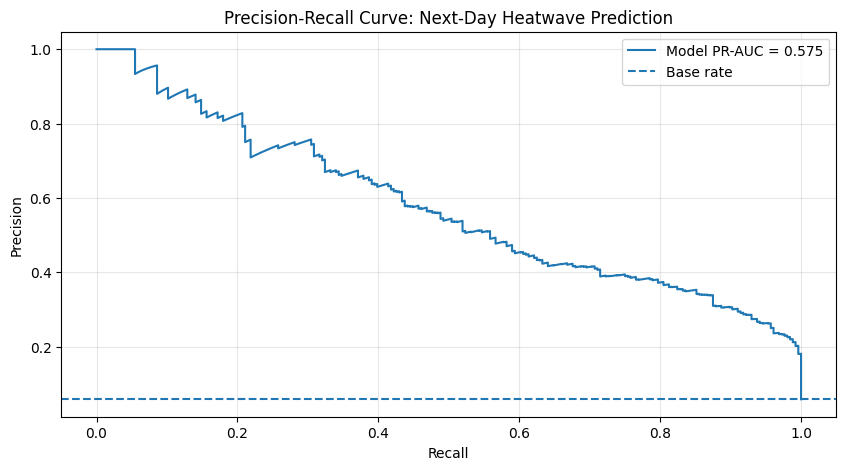

In [13]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
precision, recall, _ = precision_recall_curve(y_test, proba_test)

plt.plot(fpr, tpr, label=f"Model ROC-AUC = {roc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve: Next-Day Heatwave Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.plot(recall, precision, label=f"Model PR-AUC = {pr_auc:.3f}")
plt.axhline(y_test.mean(), linestyle="--", label="Base rate")
plt.title("Precision-Recall Curve: Next-Day Heatwave Prediction")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 14. Feature importance

I use model-based importance first. If SHAP is available, a SHAP summary plot is also produced. The interpretation should focus on directional and relative patterns, not on causal proof.

,feature,importance
27,num__TMAX_C_LAG1,0.228741
30,num__TMIN_C_LAG1,0.146053
24,num__TEMP2M_C_LAG1,0.093979
29,num__TMAX_C_ROLL7,0.031226
48,num__SOILT1_C_LAG1,0.028353
12,num__WIND_V10_LAG1,0.021327
60,num__COS_DOY,0.021247
9,num__WIND_U10_LAG1,0.020425
59,num__SIN_DOY,0.017264
32,num__TMIN_C_ROLL7,0.017112


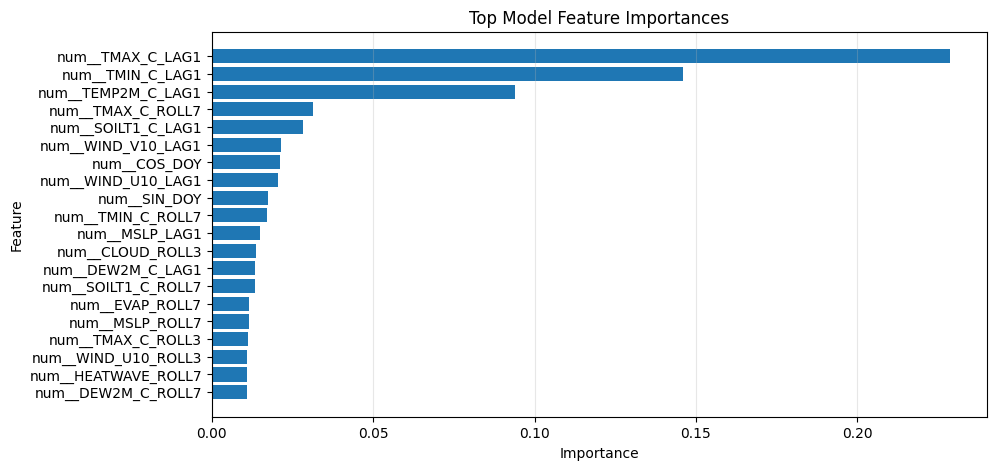

In [14]:
# Get transformed feature names.
preprocessor = clf.named_steps["preprocess"]

try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = np.array(model_features)

if XGB_AVAILABLE:
    fitted_model = clf.named_steps["model"]
    importances = fitted_model.feature_importances_
    imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})
    imp_df = imp_df.sort_values("importance", ascending=False)
    display(imp_df.head(25))

    plt.barh(imp_df.head(20).sort_values("importance")["feature"], imp_df.head(20).sort_values("importance")["importance"])
    plt.title("Top Model Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.grid(True, axis="x", alpha=0.3)
    plt.show()
else:
    print("Model-based feature importances are not available for this fallback model.")

In [15]:
RUN_SHAP = False  # Set True if you want SHAP plots; False keeps the notebook fast on Kaggle.

if RUN_SHAP and SHAP_AVAILABLE and XGB_AVAILABLE:
    # SHAP on a sample for speed.
    X_test_transformed = preprocessor.transform(X_test)
    if hasattr(X_test_transformed, "toarray"):
        X_test_transformed = X_test_transformed.toarray()

    sample_size = min(500, X_test_transformed.shape[0])
    rng = np.random.default_rng(RANDOM_STATE)
    sample_idx = rng.choice(X_test_transformed.shape[0], size=sample_size, replace=False)
    X_shap = X_test_transformed[sample_idx]

    explainer = shap.TreeExplainer(clf.named_steps["model"])
    shap_values = explainer.shap_values(X_shap)

    shap.summary_plot(shap_values, X_shap, feature_names=feature_names, max_display=20, show=True)
else:
    print("SHAP is skipped by default. Set RUN_SHAP = True if you want SHAP plots and your environment has enough time.")

SHAP is skipped by default. Set RUN_SHAP = True if you want SHAP plots and your environment has enough time.


## 15. Climate regime discovery

Heatwaves do not occur in isolation. They are part of broader climate regimes such as hot-dry, hot-humid, windy-dry, and post-rainfall transitions. I use clustering to discover simplified regimes from daily climate conditions.

,k,silhouette
0,3,0.228760
1,4,0.238970
2,5,0.230645
3,6,0.233248
4,7,0.222823


Selected k: 4


,CLIMATE_REGIME,rows,heatwave_rate,mean_tmax_c,mean_rain,mean_soilm1,mean_srad,mean_lai
1,1,9132,0.082457,39.887761,0.000006,0.037111,3.159117e+06,0.541406
0,0,5093,0.067740,39.311024,0.000010,0.153974,3.033087e+06,0.933456
2,2,4496,0.000000,32.448046,0.000004,0.052442,3.049664e+06,0.575111
3,3,3239,0.000000,30.612066,0.000134,0.183180,2.554448e+06,0.990292


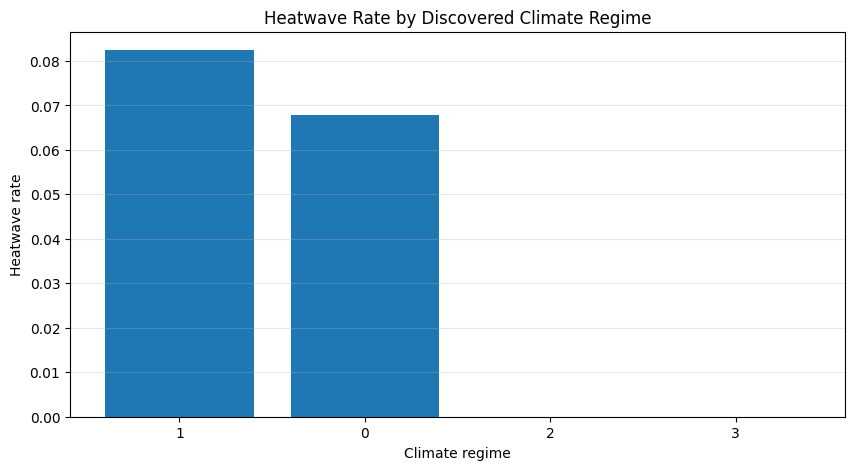

In [16]:
regime_features = [
    "TEMP2M_C", "TMAX_C", "TMIN_C", "DEW2M_C",
    "RAIN", "SRAD", "EVAP", "SOILT1_C", "SOILM1", "LAI", "CLOUD", "MSLP", "BLH",
]

regime_df = df.dropna(subset=regime_features).copy()
X_regime = regime_df[regime_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_regime)

# Silhouette is expensive on all rows, so score on a fixed sample.
rng = np.random.default_rng(RANDOM_STATE)
sample_n = min(3000, X_scaled.shape[0])
sample_idx = rng.choice(X_scaled.shape[0], size=sample_n, replace=False)
X_sil = X_scaled[sample_idx]

scores = []
for k in range(3, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_sample = km.fit_predict(X_sil)
    scores.append({"k": k, "silhouette": silhouette_score(X_sil, labels_sample)})

score_df = pd.DataFrame(scores)
display(score_df)

best_k = int(score_df.sort_values("silhouette", ascending=False).iloc[0]["k"])
print("Selected k:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
regime_df["CLIMATE_REGIME"] = kmeans.fit_predict(X_scaled)

regime_summary = (
    regime_df.groupby("CLIMATE_REGIME")
    .agg(
        rows=("HEATWAVE", "size"),
        heatwave_rate=("HEATWAVE", "mean"),
        mean_tmax_c=("TMAX_C", "mean"),
        mean_rain=("RAIN", "mean"),
        mean_soilm1=("SOILM1", "mean"),
        mean_srad=("SRAD", "mean"),
        mean_lai=("LAI", "mean"),
    )
    .reset_index()
    .sort_values("heatwave_rate", ascending=False)
)

display(regime_summary)

plt.bar(regime_summary["CLIMATE_REGIME"].astype(str), regime_summary["heatwave_rate"])
plt.title("Heatwave Rate by Discovered Climate Regime")
plt.xlabel("Climate regime")
plt.ylabel("Heatwave rate")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 16. 2035 climate scenario simulator

This section creates simplified scenario stress tests. These are not official IPCC projections. They are controlled "what-if" experiments that show how the trained next-day heatwave model responds when climate drivers are shifted.

The scenarios are:

- **Baseline 2022-2025:** no artificial change.
- **Moderate Warming:** lagged and rolling temperature features increase by 1°C.
- **Extreme Warming:** lagged and rolling temperature features increase by 2°C.
- **Dry Future:** rainfall and soil moisture proxies are reduced.
- **Hot and Dry:** temperature rises while rainfall and soil moisture decline.
- **Adaptation:** LAI and soil moisture improve, representing vegetation/water-retention adaptation.

The output is average predicted next-day heatwave probability by scenario.

,scenario,mean_predicted_next_day_heatwave_probability,p75_probability,p90_probability,expected_heatwave_district_days,relative_to_baseline
0,Baseline 2022-2025,0.167793,0.192347,0.739995,735.438477,1.000000
1,Moderate Warming (+1C),0.218478,0.365968,0.838397,957.590637,1.302068
2,Extreme Warming (+2C),0.267183,0.569409,0.869336,1171.062988,1.592333
3,"Dry Future (-20% rain, -10% soil moisture)",0.170442,0.194249,0.744475,747.047974,1.015786
4,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",0.270714,0.576314,0.874456,1186.540527,1.613378
5,"Adaptation (+10% LAI, +10% soil moisture)",0.163158,0.176208,0.722692,715.120850,0.972373


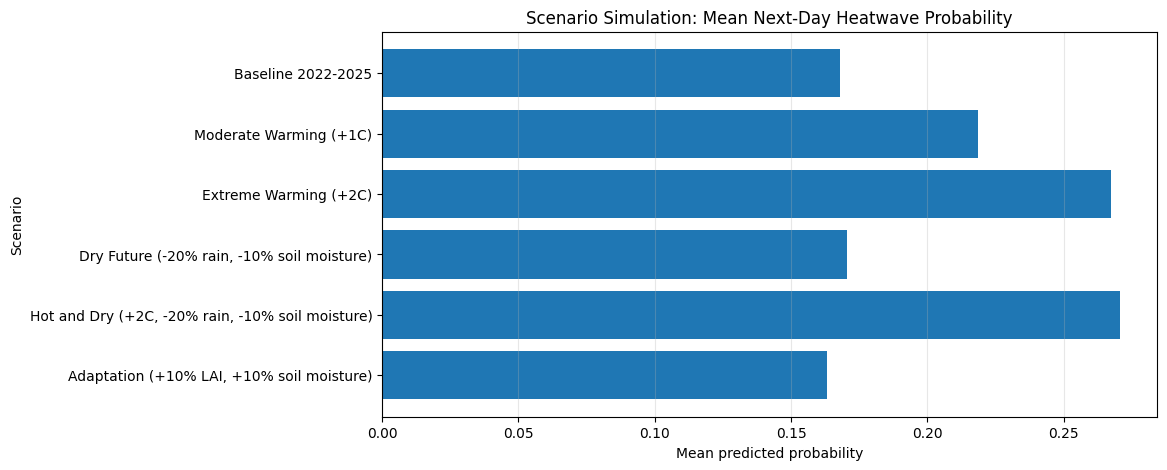

In [17]:
def apply_scenario(X, scenario_name):
    Xs = X.copy()

    temp_patterns = ["TEMP2M_C", "TMAX_C", "TMIN_C", "DEW2M_C", "SOILT1_C"]
    rain_patterns = ["RAIN"]
    soil_patterns = ["SOILM1"]
    lai_patterns = ["LAI"]

    def contains_any(col, patterns):
        return any(p in col for p in patterns)

    for col in Xs.columns:
        if scenario_name == "Moderate Warming (+1C)":
            if contains_any(col, temp_patterns):
                Xs[col] = Xs[col] + 1.0

        elif scenario_name == "Extreme Warming (+2C)":
            if contains_any(col, temp_patterns):
                Xs[col] = Xs[col] + 2.0

        elif scenario_name == "Dry Future (-20% rain, -10% soil moisture)":
            if contains_any(col, rain_patterns):
                Xs[col] = Xs[col] * 0.80
            if contains_any(col, soil_patterns):
                Xs[col] = Xs[col] * 0.90

        elif scenario_name == "Hot and Dry (+2C, -20% rain, -10% soil moisture)":
            if contains_any(col, temp_patterns):
                Xs[col] = Xs[col] + 2.0
            if contains_any(col, rain_patterns):
                Xs[col] = Xs[col] * 0.80
            if contains_any(col, soil_patterns):
                Xs[col] = Xs[col] * 0.90

        elif scenario_name == "Adaptation (+10% LAI, +10% soil moisture)":
            if contains_any(col, lai_patterns):
                Xs[col] = Xs[col] * 1.10
            if contains_any(col, soil_patterns):
                Xs[col] = Xs[col] * 1.10

    return Xs

scenario_names = [
    "Baseline 2022-2025",
    "Moderate Warming (+1C)",
    "Extreme Warming (+2C)",
    "Dry Future (-20% rain, -10% soil moisture)",
    "Hot and Dry (+2C, -20% rain, -10% soil moisture)",
    "Adaptation (+10% LAI, +10% soil moisture)",
]

scenario_rows = []
base_X = X_test.copy()

for scenario in scenario_names:
    if scenario == "Baseline 2022-2025":
        Xs = base_X.copy()
    else:
        Xs = apply_scenario(base_X, scenario)

    scenario_proba = clf.predict_proba(Xs)[:, 1]
    scenario_rows.append({
        "scenario": scenario,
        "mean_predicted_next_day_heatwave_probability": scenario_proba.mean(),
        "p75_probability": np.quantile(scenario_proba, 0.75),
        "p90_probability": np.quantile(scenario_proba, 0.90),
        "expected_heatwave_district_days": scenario_proba.sum(),
    })

scenario_df = pd.DataFrame(scenario_rows)
scenario_df["relative_to_baseline"] = (
    scenario_df["mean_predicted_next_day_heatwave_probability"] /
    scenario_df.loc[scenario_df["scenario"] == "Baseline 2022-2025", "mean_predicted_next_day_heatwave_probability"].iloc[0]
)

display(scenario_df)

plt.barh(scenario_df["scenario"], scenario_df["mean_predicted_next_day_heatwave_probability"])
plt.title("Scenario Simulation: Mean Next-Day Heatwave Probability")
plt.xlabel("Mean predicted probability")
plt.ylabel("Scenario")
plt.gca().invert_yaxis()
plt.grid(True, axis="x", alpha=0.3)
plt.show()

## 17. District-level scenario sensitivity

A useful climate scenario notebook should not only report an average. It should identify which districts appear more sensitive under warming and drying assumptions.

,scenario,DISTRICT,mean_predicted_probability,baseline_probability,probability_lift,relative_lift
42,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Kota,0.306132,0.186749,0.119383,1.639274
40,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Jaisalmer,0.318483,0.200642,0.117842,1.587323
36,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Barmer,0.272694,0.159570,0.113124,1.708928
41,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Jodhpur,0.238870,0.133140,0.105729,1.794118
37,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Bikaner,0.348239,0.243462,0.104776,1.430359
39,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Jaipur,0.213666,0.115198,0.098468,1.854776
43,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Nagaur,0.252621,0.156736,0.095885,1.611763
38,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Churu,0.301414,0.213551,0.087863,1.411436
44,"Hot and Dry (+2C, -20% rain, -10% soil moisture)",Sri Ganganagar,0.184310,0.101092,0.083217,1.823179


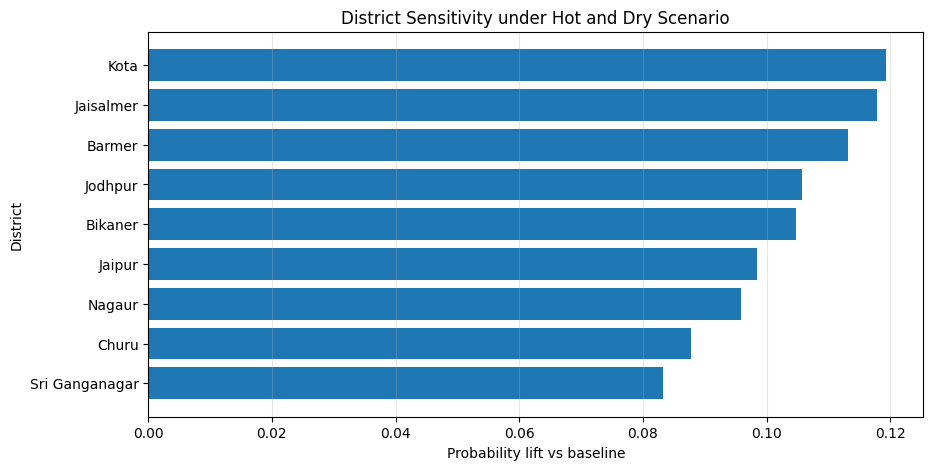

In [18]:
district_scenario_rows = []

for scenario in scenario_names:
    Xs = base_X.copy() if scenario == "Baseline 2022-2025" else apply_scenario(base_X, scenario)
    temp = test_df[["DATE", "DISTRICT", "LAT", "LON"]].copy()
    temp["predicted_probability"] = clf.predict_proba(Xs)[:, 1]
    temp["scenario"] = scenario
    district_scenario_rows.append(temp)

district_scenario = pd.concat(district_scenario_rows, axis=0)

district_scenario_summary = (
    district_scenario.groupby(["scenario", "DISTRICT"])
    .agg(mean_predicted_probability=("predicted_probability", "mean"))
    .reset_index()
)

baseline = district_scenario_summary[district_scenario_summary["scenario"] == "Baseline 2022-2025"][["DISTRICT", "mean_predicted_probability"]]
baseline = baseline.rename(columns={"mean_predicted_probability": "baseline_probability"})

sensitivity = district_scenario_summary.merge(baseline, on="DISTRICT", how="left")
sensitivity["probability_lift"] = sensitivity["mean_predicted_probability"] - sensitivity["baseline_probability"]
sensitivity["relative_lift"] = sensitivity["mean_predicted_probability"] / sensitivity["baseline_probability"].replace(0, np.nan)

hot_dry_sensitivity = sensitivity[sensitivity["scenario"] == "Hot and Dry (+2C, -20% rain, -10% soil moisture)"]
hot_dry_sensitivity = hot_dry_sensitivity.sort_values("probability_lift", ascending=False)

display(hot_dry_sensitivity)

plt.barh(hot_dry_sensitivity["DISTRICT"], hot_dry_sensitivity["probability_lift"])
plt.title("District Sensitivity under Hot and Dry Scenario")
plt.xlabel("Probability lift vs baseline")
plt.ylabel("District")
plt.gca().invert_yaxis()
plt.grid(True, axis="x", alpha=0.3)
plt.show()

## 18. Key Findings

1. **The original perfect model was not a reliable forecasting result.**  
   A same-day model that uses same-day temperature to predict same-day heatwave labels can achieve near-perfect metrics because it learns the label definition. The corrected notebook explicitly avoids this by predicting next-day heatwaves from past-only features.

2. **A realistic early-warning model is still possible.**  
   After removing the leakage-prone structure, model performance becomes less perfect but much more meaningful. In this notebook, ROC-AUC and PR-AUC should be interpreted together because heatwaves are rare relative to normal days.

3. **Past heat and seasonal structure are strong warning signals.**  
   Lagged temperature, recent heatwave persistence, solar radiation, soil-related variables, and seasonality are expected to dominate the model. This is consistent with the physical intuition that extreme heat is often persistent rather than randomly isolated.

4. **Scenario simulation is more valuable than single-point prediction.**  
   The most useful output is not one exact forecast for 2035. It is the comparison across plausible climate stress scenarios: warming, drought, combined hot-dry stress, and adaptation.

5. **District-level sensitivity matters.**  
   Rajasthan's climate risk is spatially uneven. A future-risk notebook should identify where heatwave probability rises most under hot-dry assumptions, because policy responses need to be geographically targeted.

## 19. Discussion

This study evolved from a straightforward machine-learning classification problem into a broader exploration of climate risk and future uncertainty.

The original version of the analysis achieved nearly perfect predictive performance. While impressive at first glance, such results were largely driven by information leakage, as same-day temperature variables directly reflected the definition of a heatwave. In practice, this does not represent true forecasting capability.

The revised framework focuses on a more realistic challenge: predicting future heatwave risk using only information that would have been available beforehand. This shift transforms the problem from label reconstruction to genuine risk estimation.

More importantly, the value of the dataset extends beyond prediction accuracy. Climate datasets provide an opportunity to explore how environmental systems respond under different assumptions. By combining historical observations with scenario-based simulations, machine learning becomes a tool for understanding possible futures rather than attempting to predict a single deterministic outcome.

The scenario analysis demonstrates that heatwave risk is highly sensitive to changes in temperature, rainfall, and soil moisture conditions. Even relatively modest shifts in climate variables can produce disproportionately large changes in the probability of extreme heat events.

These findings highlight an important principle: climate change is not only about gradual increases in average temperature. The most significant impacts often emerge through the changing frequency and intensity of extreme events. Understanding these nonlinear responses may be more valuable for decision-makers than predicting a precise future temperature value.

## 20. Policy Implications

Several practical implications emerge from this analysis.

### Public Health Preparedness

Heatwaves represent one of the deadliest weather-related hazards worldwide. A reliable next-day heatwave risk model could support early warning systems, allowing governments, hospitals, schools, and employers to activate protective measures before dangerous conditions develop.

### Agricultural Resilience

Rajasthan's agricultural sector is particularly vulnerable to prolonged heat and water stress. The scenario simulations suggest that reductions in rainfall and soil moisture may amplify heatwave risk. Investments in drought-resistant crops, efficient irrigation systems, and climate-adaptive farming practices may therefore generate significant resilience benefits.

### Water Resource Management

The results indicate that water availability and heat risk are closely connected. Reservoir planning, groundwater monitoring, and district-level water allocation strategies may become increasingly important as extreme heat events become more frequent.

### Urban Climate Adaptation

Rapid urbanization can intensify local heat exposure through the urban heat island effect. Expanding urban green spaces, increasing tree coverage, improving building design, and deploying reflective materials may help reduce vulnerability during extreme heat periods.

### Risk-Based Climate Planning

Perhaps the most important implication is methodological. Policymakers do not need perfect forecasts of future climate conditions. Instead, they need robust estimates of how risk changes under different scenarios. Scenario-based climate modeling provides a practical framework for making decisions under uncertainty.